In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


## **Data preprocessing**

In [32]:
df=pd.read_csv('customer_data.csv')
df

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29
...,...,...,...,...,...,...,...
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17


In [33]:
# 2. Data Collection / Load Dataset

df = pd.read_csv("customer_data.csv")

print(df.head())

print(df.shape)

print(df.info())

print(df.describe())

   CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0           1   68  Female      Houston              24            595.11   
1           2   35    Male      Phoenix              29           2901.57   
2           3   60    Male      Phoenix              19           4109.95   
3           4   63  Female      Chicago              27           2324.75   
4           5   42    Male  Los Angeles              15           1122.67   

  LastPurchaseDate  
0       2023-01-01  
1       2023-01-08  
2       2023-01-15  
3       2023-01-22  
4       2023-01-29  
(100, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    object 
 3   Location          100 non-null    object 
 4   TotalPurchas

In [34]:
# 3. Data Preprocessing


# Check missing values

print(df.isnull().sum())


# Remove duplicate records

df = df.drop_duplicates()


# Standardize Location Names

df['Location'] = df['Location'].str.title()


# Convert Date column

df['LastPurchaseDate'] = pd.to_datetime(df['LastPurchaseDate'])


# Create Age Groups for Customer Segmentation

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17,30,45,60,100],
    labels=['18-30','31-45','46-60','60+']
)


print(df.head())

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64
   CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0           1   68  Female      Houston              24            595.11   
1           2   35    Male      Phoenix              29           2901.57   
2           3   60    Male      Phoenix              19           4109.95   
3           4   63  Female      Chicago              27           2324.75   
4           5   42    Male  Los Angeles              15           1122.67   

  LastPurchaseDate AgeGroup  
0       2023-01-01      60+  
1       2023-01-08    31-45  
2       2023-01-15    46-60  
3       2023-01-22      60+  
4       2023-01-29    31-45  


# 4. Data Analysis


## Average Purchase Value by Age Group


AgeGroup
18-30    2606.100833
31-45    2391.559615
46-60    2563.377586
60+      2397.805714
Name: TotalAmountSpent, dtype: float64


/tmp/ipykernel_8493/940911272.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_purchase = df.groupby(


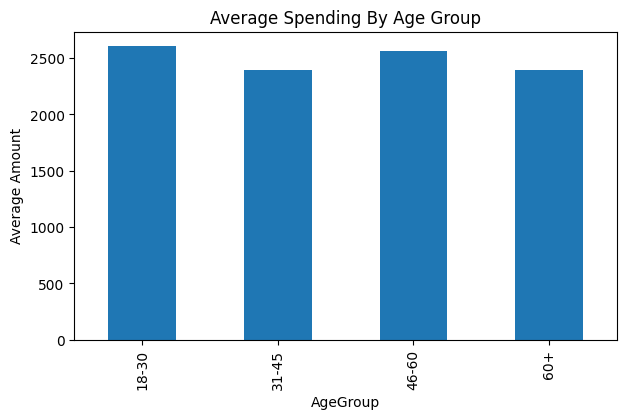

In [35]:
age_purchase = df.groupby(
    'AgeGroup'
)['TotalAmountSpent'].mean()


print(age_purchase)


age_purchase.plot(
    kind='bar',
    figsize=(7,4)
)

plt.title("Average Spending By Age Group")
plt.ylabel("Average Amount")
plt.show()

# Customer Distribution by Gender

Gender
Female    50
Male      50
Name: count, dtype: int64


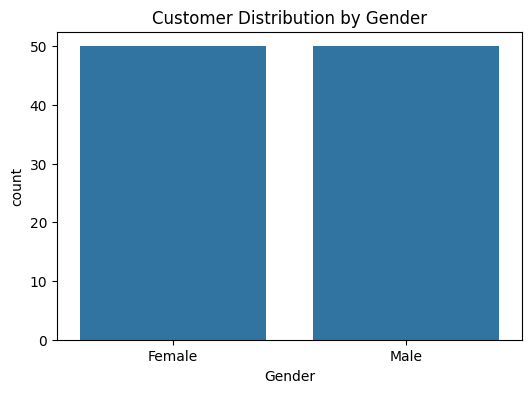

In [36]:
gender_count = df['Gender'].value_counts()

print(gender_count)


plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x='Gender'
)

plt.title("Customer Distribution by Gender")
plt.show()

# Customer Distribution by Location


Location
Houston        32
Phoenix        21
Chicago        18
New York       15
Los Angeles    14
Name: count, dtype: int64


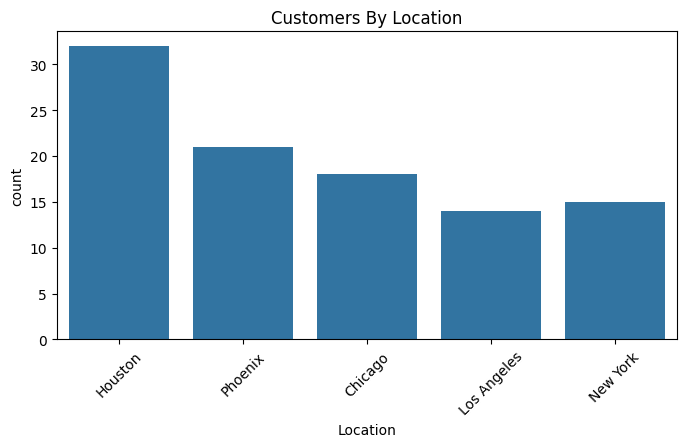

In [37]:
location_count = df['Location'].value_counts()

print(location_count)

plt.figure(figsize=(8,4))
sns.countplot(
    data=df,
    x='Location'
)

plt.xticks(rotation=45)
plt.title("Customers By Location")
plt.show()


# ○	Average Purchase Value by age and gender.

AgeGroup
18-30    2606.100833
31-45    2391.559615
46-60    2563.377586
60+      2397.805714
Name: TotalAmountSpent, dtype: float64


/tmp/ipykernel_8493/3107823475.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_purchase = df.groupby('AgeGroup')['TotalAmountSpent'].mean()


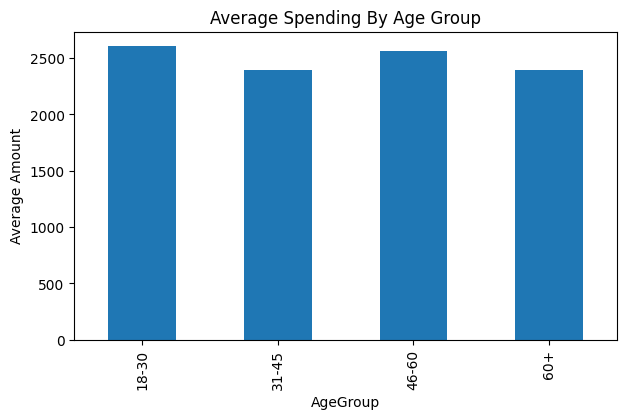

In [38]:
age_purchase = df.groupby('AgeGroup')['TotalAmountSpent'].mean()

print(age_purchase)

age_purchase.plot(
    kind='bar',
    figsize=(7,4)
)

plt.title("Average Spending By Age Group")
plt.ylabel("Average Amount")
plt.show()

Gender
Female    2263.2020
Male      2725.1748
Name: TotalAmountSpent, dtype: float64


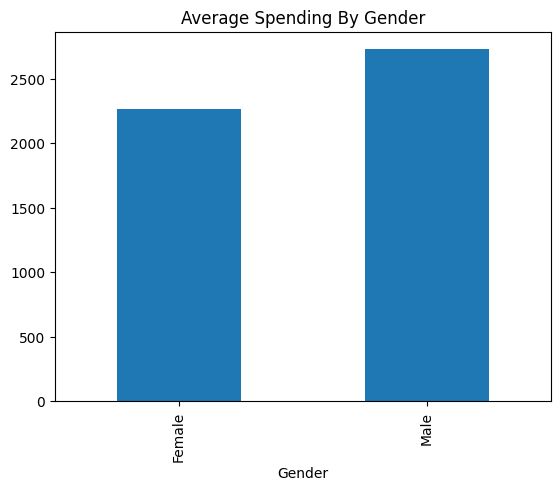

In [39]:
gender_purchase = df.groupby('Gender')['TotalAmountSpent'].mean()
print(gender_purchase)

gender_purchase.plot(
    kind='bar'
)

plt.title("Average Spending By Gender")
plt.show()

# ○	Total Purchase Amount by location.

Location
Houston        80502.02
Phoenix        59964.31
Chicago        46500.07
New York       31409.18
Los Angeles    31043.26
Name: TotalAmountSpent, dtype: float64


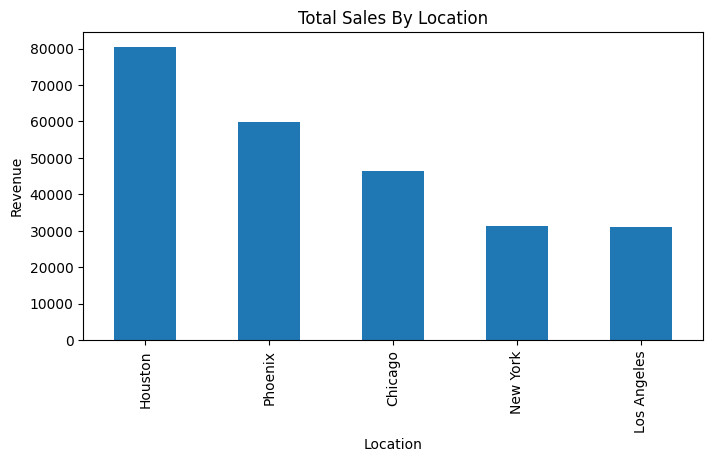

In [40]:
location_sales = df.groupby(
    'Location'
)['TotalAmountSpent'].sum().sort_values(
    ascending=False
)


print(location_sales)


location_sales.plot(
    kind='bar',
    figsize=(8,4)
)
plt.title("Total Sales By Location")
plt.ylabel("Revenue")
plt.show()


#  Customer Lifetime Value Analysis (CLV)

In [41]:
df['CLV'] = (
    df['TotalPurchases']
    *
    df['TotalAmountSpent']
)


high_value_customer = df.sort_values(
    by='CLV',
    ascending=False
)


print(
    high_value_customer[
        [
            'CustomerID',
            'Age',
            'Gender',
            'Location',
            'CLV'
        ]
    ].head()
)


    CustomerID  Age  Gender Location        CLV
78          79   43    Male  Chicago  142989.30
33          34   43  Female  Chicago  125085.52
13          14   34    Male  Houston  118757.52
88          89   58    Male  Chicago  114510.51
17          18   42    Male  Houston  113666.70


Gender
Female    17.10
Male      16.14
Name: TotalPurchases, dtype: float64


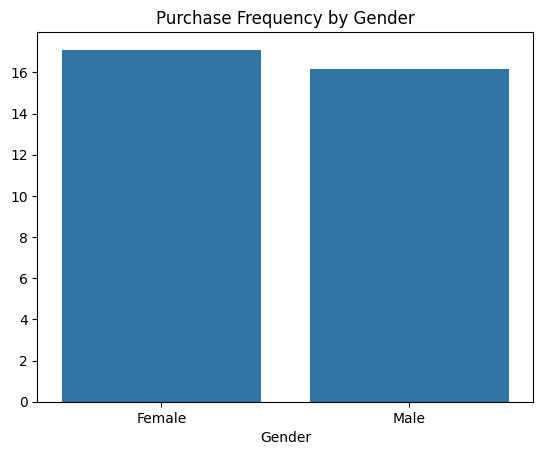

In [42]:
purchase_frequency = df.groupby(
    'Gender'
)['TotalPurchases'].mean()


print(purchase_frequency)


sns.barplot(
    x=purchase_frequency.index,
    y=purchase_frequency.values
)

plt.title("Purchase Frequency by Gender")
plt.show()


# ○	Churn Rate and customer loyalty based on purchase frequency.

   CustomerID  TotalPurchases         CustomerType
0           1              24       Loyal Customer
1           2              29       Loyal Customer
2           3              19       Loyal Customer
3           4              27       Loyal Customer
4           5              15  Churn Risk Customer


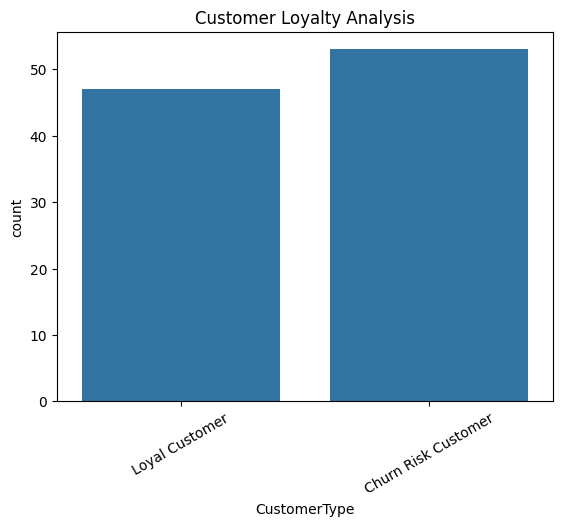

In [43]:
avg_purchase = df['TotalPurchases'].mean()


df['CustomerType'] = np.where(
    df['TotalPurchases'] >= avg_purchase,
    "Loyal Customer",
    "Churn Risk Customer"
)


print(
    df[
        [
            'CustomerID',
            'TotalPurchases',
            'CustomerType'
        ]
    ].head()
)


sns.countplot(
    data=df,
    x='CustomerType'
)

plt.title("Customer Loyalty Analysis")
plt.xticks(rotation=30)
plt.show()

# 4.	Insights and Business Recommendations: (Your view points based on data analysis/report)

Insight 1: Gender Based Trends
Male customers have higher average spending.
Average male spending: ₹2725
Average female spending: ₹2263

Recommendation:
Create premium product campaigns and personalized recommendations for male customers to increase revenue.

Insight 2: Location Based Customer Value

Top revenue generating locations:

Houston → ₹80,502
Phoenix → ₹59,964
Chicago → ₹46,500

Recommendation:
Increase advertisements and special offers in Houston and Phoenix because these cities contain high-value customers.

Insight 3

Houston has the highest revenue.

Recommendation

Increase marketing campaigns in Houston.

Insight 4

Customers with high purchase frequency are loyal customers.

Recommendation

Provide reward points and membership.

Insight 5: Customer Loyalty

Customers with higher purchase frequency are loyal customers.

Recommendation:
Give personalized offers and membership programs to loyal customers and re-engagement discounts to low-frequency customers.